In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv(r'data/patient_records.csv')
print(df.columns.tolist())

['patient_id', 'first_name', 'last_name', 'gender', 'date_of_birth', 'age', 'blood_group', 'preferred_language', 'city', 'state', 'insurance_provider', 'insurance_plan', 'admission_date', 'discharge_date', 'length_of_stay_days', 'admission_type', 'department', 'attending_physician', 'primary_diagnosis', 'icd10_code', 'secondary_diagnosis', 'comorbidity_count', 'icu_admission', 'procedure_performed', 'height_cm', 'weight_kg', 'bmi', 'systolic_bp', 'diastolic_bp', 'heart_rate_bpm', 'temperature_c', 'spo2_pct', 'blood_glucose_mgdl', 'hba1c_pct', 'total_cholesterol_mgdl', 'hemoglobin_gdl', 'creatinine_mgdl', 'smoking_status', 'alcohol_use', 'known_allergy', 'primary_medication', 'lab_tests_ordered', 'total_bill_inr', 'insurance_covered_inr', 'patient_paid_inr', 'payment_status', 'discharge_disposition', 'readmitted_30d', 'risk_score', 'patient_satisfaction']


In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 50 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   patient_id              100000 non-null  str    
 1   first_name              100000 non-null  str    
 2   last_name               100000 non-null  str    
 3   gender                  100000 non-null  str    
 4   date_of_birth           100000 non-null  str    
 5   age                     100000 non-null  int64  
 6   blood_group             100000 non-null  str    
 7   preferred_language      100000 non-null  str    
 8   city                    100000 non-null  str    
 9   state                   100000 non-null  str    
 10  insurance_provider      100000 non-null  str    
 11  insurance_plan          100000 non-null  str    
 12  admission_date          100000 non-null  str    
 13  discharge_date          100000 non-null  str    
 14  length_of_stay_days     100000 n

we checked the datatypes of columns and names 

In [4]:
print(df.duplicated().sum())

0


there are no duplicate values 

In [5]:
missing_per = df.isnull().mean()*100
missing_per = missing_per.sort_values(ascending=False)
print(missing_per.head(6))

hba1c_pct                 12.145
total_cholesterol_mgdl     8.098
creatinine_mgdl            3.914
hemoglobin_gdl             3.000
blood_glucose_mgdl         2.887
date_of_birth              0.000
dtype: float64


we are not filling this data because doctor might not have discribed this tests so we can keep this empty 

In [6]:
for col in ["date_of_birth", "admission_date", "discharge_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")


print(df[["date_of_birth", "admission_date", "discharge_date"]].isna().sum())

date_of_birth     0
admission_date    0
discharge_date    0
dtype: int64


Converted all dates from string to date and time

In [7]:
df['age'].describe()
age_df = df['age']

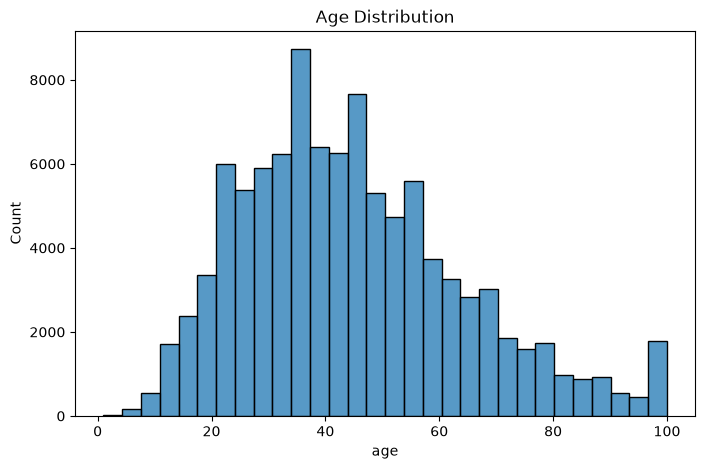

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(age_df, bins=30)
plt.title('Age Distribution')
plt.show()

as we can see that higest number of people are in between 30 to 45 age are mostly

In [9]:
bins = [0,18,30,45,60,100]
labels = ['0-18','19-30','31-45','46-60','60+']

age_df = pd.cut(age_df,
                    bins=bins,
                   labels=labels)


In [10]:
print(age_df.value_counts().sort_index())

age
0-18      5844
19-30    19628
31-45    31540
46-60    23128
60+      19860
Name: count, dtype: int64


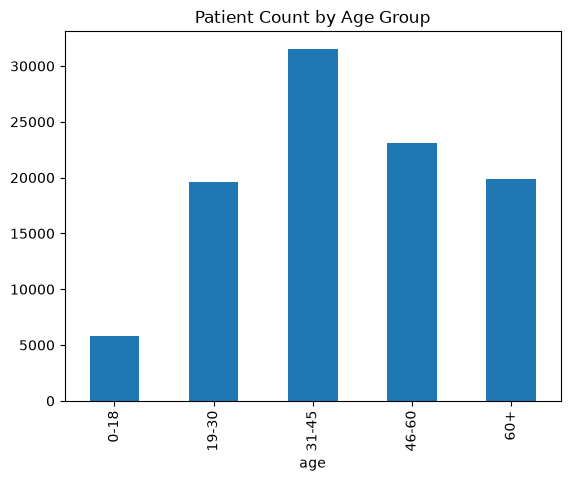

In [11]:
age_df.value_counts().sort_index().plot(kind='bar')
plt.title('Patient Count by Age Group')
plt.show()

most patient are in between 31 to 45 group 

gender
Male      50229
Female    49282
Other       489
Name: count, dtype: int64
gender
Male      50.229
Female    49.282
Other      0.489
Name: proportion, dtype: float64


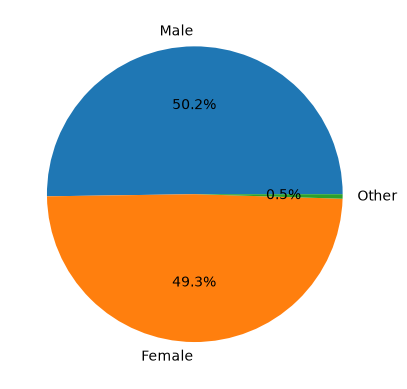

In [12]:
df_gender = df['gender']
print(df_gender.value_counts())
print(df_gender.value_counts(normalize=True)*100)

df_gender.value_counts().plot(kind='pie',autopct='%1.1f%%')
plt.ylabel('')
plt.show()

gender
Female    48134.904252
Other     48091.907853
Male      46625.529639
Name: total_bill_inr, dtype: float64


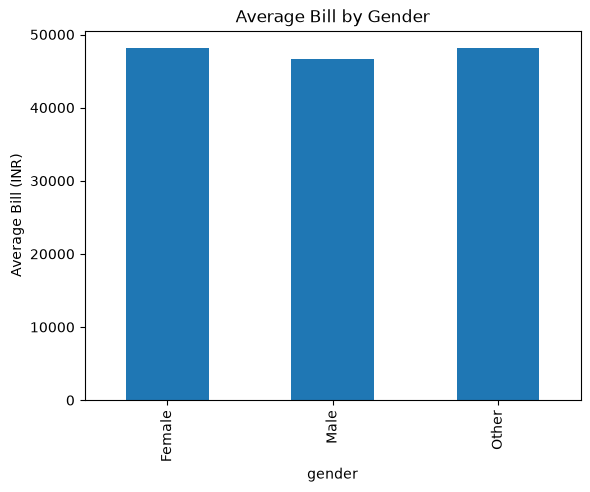

In [13]:
df_gender_and_bills = df.groupby('gender')['total_bill_inr'].mean().sort_values(ascending=False)
print(df_gender_and_bills)
df.groupby('gender')['total_bill_inr'].mean().plot(kind='bar')
plt.title('Average Bill by Gender')
plt.ylabel('Average Bill (INR)')
plt.show()


state
Maharashtra       17846
Delhi              9959
Tamil Nadu         9312
Telangana          8881
Gujarat            7890
Karnataka          7830
West Bengal        6905
Madhya Pradesh     5940
Kerala             5327
Andhra Pradesh     5043
Rajasthan          4112
Uttar Pradesh      3997
Bihar              3068
Assam              1951
Chandigarh         1939
Name: count, dtype: int64


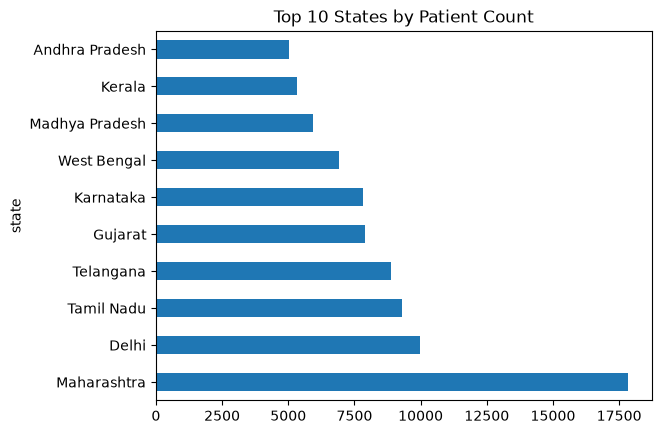

In [14]:
state_count = df['state'].value_counts()
print(state_count)
# print(state_count.head(10))
state_count.head(10).plot(kind='barh')
plt.title('Top 10 States by Patient Count')
plt.show()

blood_group
B+     31965
O+     26871
A+     21875
AB+     7029
B-      4102
O-      4077
A-      2996
AB-     1085
Name: count, dtype: int64
blood_group
B+     31.965
O+     26.871
A+     21.875
AB+     7.029
B-      4.102
O-      4.077
A-      2.996
AB-     1.085
Name: proportion, dtype: float64


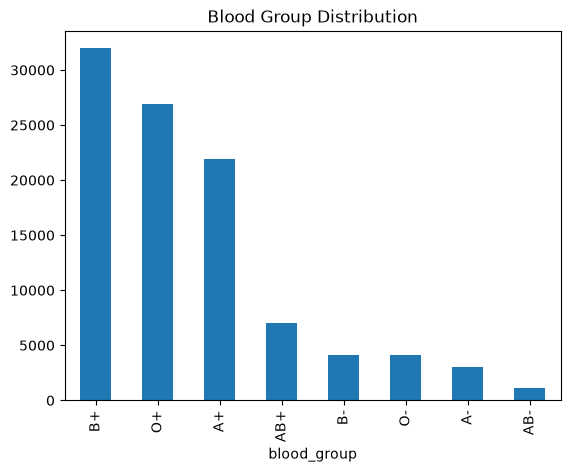

In [15]:
print(df['blood_group'].value_counts())
print(df['blood_group'].value_counts(normalize=True)*100)
df['blood_group'].value_counts().plot(kind='bar')
plt.title('Blood Group Distribution')
plt.show()

readmitted_30d
0    91694
1     8306
Name: count, dtype: int64
readmitted_30d
0    91.694
1     8.306
Name: proportion, dtype: float64


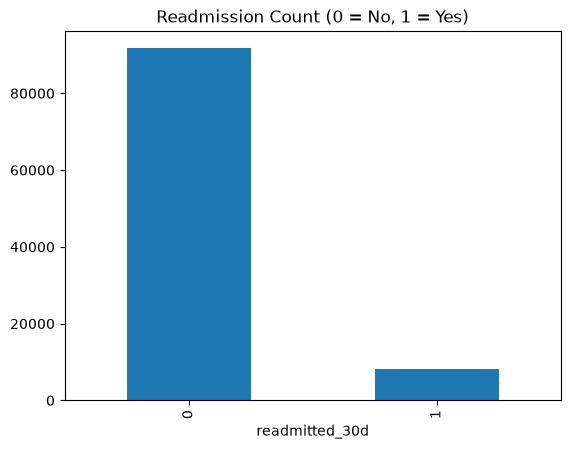

In [16]:
# How balanced is your target
print(df["readmitted_30d"].value_counts())
print(df["readmitted_30d"].value_counts(normalize=True) * 100)

# Visualize
df["readmitted_30d"].value_counts().plot(kind="bar")
plt.title("Readmission Count (0 = No, 1 = Yes)")
plt.show()

In [17]:
print(df["readmitted_30d"].value_counts())
print(df["readmitted_30d"].value_counts(normalize=True) * 100)

readmitted_30d
0    91694
1     8306
Name: count, dtype: int64
readmitted_30d
0    91.694
1     8.306
Name: proportion, dtype: float64


In [18]:
df[["age", "bmi", "risk_score", "total_bill_inr", 
    "length_of_stay_days"]].describe()

,age,bmi,risk_score,total_bill_inr,length_of_stay_days
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,44.739350,24.557105,17.551530,47376.550226,2.315120
std,19.472329,4.889479,10.747616,55780.707362,2.950848
min,1.000000,11.900000,1.000000,1723.300000,0.000000
25%,30.000000,21.200000,10.000000,14974.337500,0.000000
50%,42.000000,24.600000,15.000000,24677.800000,1.000000
75%,56.000000,27.900000,23.000000,57102.170000,3.000000
max,100.000000,43.300000,87.000000,997673.760000,45.000000


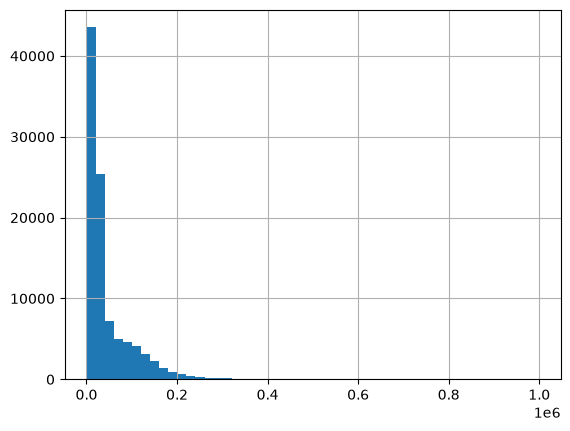

In [30]:
df["total_bill_inr"].hist(bins=50)
plt.show()

In [32]:
features = [
    "age",
    "gender",
    "length_of_stay_days",
    "admission_type",
    "department",
    "comorbidity_count",
    "icu_admission",
    "risk_score",
    "bmi",
    "systolic_bp",
    "heart_rate_bpm",
    "spo2_pct",
    "blood_glucose_mgdl",
    "smoking_status",
    "readmitted_30d"   # target
]

df_model = df[features].copy()
print(df_model.shape)
print(df_model.dtypes)

(100000, 15)
age                      int64
gender                     str
length_of_stay_days      int64
admission_type             str
department                 str
comorbidity_count        int64
icu_admission            int64
risk_score               int64
bmi                    float64
systolic_bp              int64
heart_rate_bpm           int64
spo2_pct                 int64
blood_glucose_mgdl     float64
smoking_status             str
readmitted_30d           int64
dtype: object


In [34]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in ["gender", "admission_type", "department", "smoking_status"]:
    df_model[col] = le.fit_transform(df_model[col])

print(df_model.dtypes)
print(df_model.head(3))

print(df_model["readmitted_30d"].value_counts())
print(df_model["readmitted_30d"].value_counts(normalize=True) * 100)

age                      int64
gender                   int64
length_of_stay_days      int64
admission_type           int64
department               int64
comorbidity_count        int64
icu_admission            int64
risk_score               int64
bmi                    float64
systolic_bp              int64
heart_rate_bpm           int64
spo2_pct                 int64
blood_glucose_mgdl     float64
smoking_status           int64
readmitted_30d           int64
dtype: object
   age  gender  length_of_stay_days  admission_type  department  \
0   26       0                    1               0           0   
1   23       0                    0               2           5   
2   87       0                    0               2          12   

   comorbidity_count  icu_admission  risk_score   bmi  systolic_bp  \
0                  1              0          14  34.4          159   
1                  0              0           4  37.0          125   
2                  5              0       

In [51]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Step 1 — Split features and target
X = df_model.drop(columns=["readmitted_30d"])
y = df_model["readmitted_30d"]

# Step 2 — Fill NaN BEFORE split
X = X.fillna(X.median())

# Step 3 — Confirm no NaN left
print("NaN remaining:", X.isnull().sum().sum())

# Step 4 — Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Step 5 — Train model
model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train_scaled, y_train)

# Step 6 — Evaluate
y_pred = model.predict(X_test_scaled)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

NaN remaining: 0
[[12184  6155]
 [  912   749]]
              precision    recall  f1-score   support

           0       0.93      0.66      0.78     18339
           1       0.11      0.45      0.17      1661

    accuracy                           0.65     20000
   macro avg       0.52      0.56      0.48     20000
weighted avg       0.86      0.65      0.73     20000

